### Diabetes prediction using ML
#### 1. Project Intro
This is a project aims to predict the diabetes status. 
This notebook aims to understand the dataset, identify data quality, preprocessing for further model building

#### 2. Dataset Description
The dataset is obtained from Kaggle which is of size 100000 rows and 209 columns. The target column is diabetes_status

In [4]:
import pandas as pd

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

In [6]:
# load the dataset
data = pd.read_csv('../data/diabetes_large_dataset.csv')

In [7]:
data[:5]

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes


In [8]:
#copy the dataset
df = data.copy()
df[:5]

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes


#### 3. Initial Data Exploration

In [9]:
df.shape

(100000, 209)

In [10]:
df.columns

Index(['patient_id', 'record_id', 'age', 'age_group', 'sex', 'gender',
       'ethnicity', 'race_group', 'marital_status', 'education_level',
       ...
       'diabetes_risk_score', 'overall_health_score', 'physical_health_score',
       'mental_wellbeing_score', 'quality_of_life_score',
       'chronic_condition_count', 'hospitalization_history',
       'emergency_visit_history', 'diabetes_status', 'diabetes_type'],
      dtype='str', length=209)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 209 entries, patient_id to diabetes_type
dtypes: float64(102), int64(15), str(92)
memory usage: 159.5 MB


#### Missing value analysis on entire datasset

In [12]:
# missing value analysis
missing_value_count = df.isnull().sum()

In [13]:
#missing value counts grater than zero
missing_counts = missing_value_count[missing_value_count>0]

In [14]:
#missing value percentage
missing_value_per = ((missing_counts)/len(df)*100)
missing_value_per

age                              1.993
sex                              2.005
height_cm                        4.957
weight_kg                        4.929
bmi                              2.022
waist_circumference_cm           5.120
hip_circumference_cm             5.003
fasting_glucose_mg_dl            2.061
hba1c_percent                    1.946
fasting_insulin_uIU_ml          10.178
c_peptide_ng_ml                  9.948
systolic_bp                      1.947
diastolic_bp                     2.094
pulse_pressure                   0.018
total_cholesterol_mg_dl          5.019
ldl_mg_dl                        5.001
hdl_mg_dl                        4.956
triglycerides_mg_dl              5.045
creatinine_mg_dl                 4.985
egfr_ml_min_1_73m2               5.027
urine_albumin_mg_g              10.134
alt_u_l                          5.000
ast_u_l                          5.044
hemoglobin_g_dl                  5.102
wbc_count                        5.040
platelet_count           

In [15]:
df['diabetes_status'].value_counts()

diabetes_status
0.0    70573
1.0    27407
Name: count, dtype: int64

In [16]:
df['diabetes_status'].isnull().sum()

np.int64(2020)

##### Null value handling in target column

In [17]:
#remove null value rows in the target column
df_clean = df.dropna(subset =['diabetes_status']).copy()

In [18]:
df_clean['diabetes_status'].isnull().sum()


np.int64(0)

##### Reduce the no. of rows from 100000 to 20000
For this project, a statified sample of 20,000 records was selected for analysis

In [19]:
# reduce the no. of rows to 20000
from sklearn.model_selection import train_test_split

sample_df, remaining_df = train_test_split(
    df_clean,
    train_size = 20000,
    stratify = df_clean['diabetes_status'],
    random_state = 42
)

In [20]:
sample_df.shape

(20000, 209)

In [21]:
count = sample_df['diabetes_status'].value_counts()
count

diabetes_status
0.0    14406
1.0     5594
Name: count, dtype: int64

In [22]:
per = ((count)/len(sample_df)*100)
per

diabetes_status
0.0    72.03
1.0    27.97
Name: count, dtype: float64

In [23]:
counts = sample_df.isnull().sum()

In [24]:
missing_counts = counts[counts>0]

In [25]:
len(missing_counts)

42

In [26]:
per_missing_counts = ((missing_counts)/len(sample_df)*100)

In [27]:
#create a summary of columns containing missing values
missing_summary = pd.DataFrame({
    'Missing_count' : missing_counts,
    'Missing_Percentage' : per_missing_counts
})

#sort by missing percentage
missing_summary = missing_summary.sort_values(
    by = 'Missing_Percentage', ascending = False
)
missing_summary

,Missing_count,Missing_Percentage
age_at_menopause,16515,82.575
self_management_score,2073,10.365
fasting_insulin_uIU_ml,2052,10.260
folate_ng_ml,2047,10.235
vitamin_d_ng_ml,2045,10.225
vitamin_b12_pg_ml,2043,10.215
c_peptide_ng_ml,2040,10.200
medication_adherence_percent,2018,10.090
urine_albumin_mg_g,2014,10.070
ferritin_ng_ml,1981,9.905


In [28]:
# list of column names of the entire dataset
col_list = list(sample_df.columns)


print(', '.join(col_list))

patient_id, record_id, age, age_group, sex, gender, ethnicity, race_group, marital_status, education_level, employment_status, occupation_category, income_level, annual_income, household_size, dependents, residential_area_type, urban_rural, insurance_status, height_cm, weight_kg, bmi, bmi_category, waist_circumference_cm, hip_circumference_cm, waist_to_hip_ratio, body_fat_percentage, lean_body_mass_kg, body_surface_area, resting_metabolic_rate, fasting_glucose_mg_dl, random_glucose_mg_dl, post_meal_glucose_mg_dl, two_hour_glucose_mg_dl, glucose_variability, hba1c_percent, estimated_average_glucose_mg_dl, fasting_insulin_uIU_ml, c_peptide_ng_ml, insulin_resistance_index, systolic_bp, diastolic_bp, pulse_pressure, mean_arterial_pressure, heart_rate, resting_heart_rate, hypertension_status, total_cholesterol_mg_dl, ldl_mg_dl, hdl_mg_dl, triglycerides_mg_dl, vldl_mg_dl, cholesterol_hdl_ratio, non_hdl_cholesterol, creatinine_mg_dl, bun_mg_dl, egfr_ml_min_1_73m2, urine_albumin_mg_g, urine_al

In [29]:
sample_df.dtypes

patient_id                     str
record_id                      str
age                        float64
age_group                      str
sex                            str
                            ...   
chronic_condition_count      int64
hospitalization_history        str
emergency_visit_history        str
diabetes_status            float64
diabetes_type                  str
Length: 209, dtype: object

In [30]:
#checking identifiers
print("Patient ID unique values:", sample_df['patient_id'].nunique())
print("Record ID unique values:", sample_df['record_id'].nunique())
print("Total rows:", len(sample_df))

Patient ID unique values: 20000
Record ID unique values: 20000
Total rows: 20000


##### This implies ptient id and record id are identifiers; so that we can remove it.

In [31]:
df1 = sample_df.copy()
df1.head(10)

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
47437,P047438,R00047438,39.0,31-40,Male,Male,Black,Black,Single,Less than High School,...,0.0,79.4,79.7,68.6,71.3,1,3,0,0.0,No Diabetes
50216,P050217,R00050217,43.0,41-50,Female,Female,White,White,Single,Some College,...,0.0,71.8,68.3,75.5,67.7,1,0,0,0.0,No Diabetes
89362,P089363,R00089363,52.0,51-60,Male,Male,White,White,Married,Less than High School,...,0.0,97.4,100.0,47.6,82.9,2,0,1,0.0,No Diabetes
8812,P008813,R00008813,51.0,51-60,Female,Female,White,White,Married,Bachelor,...,18.8,59.0,59.1,50.7,74.2,2,0,0,1.0,Type 2
67986,P067987,R00067987,56.0,51-60,Female,Female,White,White,Married,Master,...,31.5,59.7,56.0,79.6,83.0,7,0,0,1.0,Type 2
28051,P028052,R00028052,64.0,61-70,Female,Female,Asian,Asian,Single,High School,...,2.5,79.3,74.6,61.9,80.3,3,0,2,0.0,No Diabetes
83822,P083823,R00083823,44.0,41-50,Female,Female,Asian,Asian,Single,Less than High School,...,7.0,73.2,70.7,76.4,85.2,1,0,0,0.0,No Diabetes
11283,P011284,R00011284,44.0,41-50,Female,Female,White,White,Married,Some College,...,0.9,79.5,78.2,70.8,86.9,1,0,1,0.0,No Diabetes
34170,P034171,R00034171,49.0,41-50,Male,Male,White,White,Married,Some College,...,NaN,78.7,89.4,60.9,73.6,1,0,2,0.0,No Diabetes
7446,P007447,R00007447,61.0,61-70,Female,Female,White,White,Divorced,High School,...,0.0,72.4,74.0,29.2,52.9,3,0,0,0.0,No Diabetes


In [32]:
feature_info = pd. DataFrame({
    'Column': df1.columns,
    'Data_Types': df1.dtypes.values,
    'Missing_percentage': df1.isnull().mean().values * 100,
    'Unique_Values': df1.nunique().values
})
feature_info.head(40)

,Column,Data_Types,Missing_percentage,Unique_Values
0,patient_id,str,0.000,20000
1,record_id,str,0.000,20000
2,age,float64,2.015,73
3,age_group,str,0.000,6
4,sex,str,2.035,2
5,gender,str,0.000,3
6,ethnicity,str,0.000,8
7,race_group,str,0.000,8
8,marital_status,str,0.000,4
9,education_level,str,0.000,6


In [33]:
# Search for relevant health-related features

keywords = [
    'age', 'sex', 'gender', 'bmi', 'height', 'weight', 'waist', 'hip', 'body_fat', 'glucose', 'hba1c', 'blood_pressure', 'family_history',
    'physical_activity', 'smoking', 'diet'
]

for word in keywords:
    matches = [
        col for col in sample_df.columns
        if word.lower() in col.lower()
    ]

    if matches:
        print(f"\n{word.upper()}:")
        print(matches)


AGE:
['age', 'age_group', 'body_fat_percentage', 'estimated_average_glucose_mg_dl', 'self_management_score', 'age_at_menopause']

SEX:
['sex']

GENDER:
['gender']

BMI:
['bmi', 'bmi_category']

HEIGHT:
['height_cm']

WEIGHT:
['weight_kg']

WAIST:
['waist_circumference_cm', 'waist_to_hip_ratio']

HIP:
['hip_circumference_cm', 'waist_to_hip_ratio']

BODY_FAT:
['body_fat_percentage']

GLUCOSE:
['fasting_glucose_mg_dl', 'random_glucose_mg_dl', 'post_meal_glucose_mg_dl', 'two_hour_glucose_mg_dl', 'glucose_variability', 'estimated_average_glucose_mg_dl', 'glucose_monitoring_frequency', 'home_glucose_monitoring', 'continuous_glucose_monitor']

HBA1C:
['hba1c_percent']

BLOOD_PRESSURE:
['blood_pressure_medication']

FAMILY_HISTORY:
['family_history_diabetes', 'family_history_cardiovascular_disease', 'family_history_hypertension', 'family_history_obesity']

PHYSICAL_ACTIVITY:
['physical_activity_level']

SMOKING:
['smoking_status', 'smoking_frequency']

DIET:
['diet_quality_score', 'diet_patte

In [34]:
df1['diabetes_status'].nunique()

2

In [35]:
df1['diabetes_status'].value_counts()

diabetes_status
0.0    14406
1.0     5594
Name: count, dtype: int64

In [36]:
# removal of identifiers columns
df1.drop(columns=['patient_id','record_id'], inplace= True)

In [37]:
df1.shape

(20000, 207)

In [38]:
pd.crosstab(df1['diabetes_type'], df1['diabetes_status'])

diabetes_status,0.0,1.0
diabetes_type,,
Gestational Diabetes,0,24
No Diabetes,14406,0
Other Diabetes,0,429
Type 1,0,1
Type 2,0,5031


In [39]:
# this shows that there is a need for removal of diabetes_type due to data leakage
df1.drop('diabetes_type',axis = 1, inplace= True)

In [40]:
df1.shape

(20000, 206)

In [41]:
pd.crosstab(df1['diabetes_status'], df1['diabetes_risk_score'])


diabetes_risk_score,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,...,97.7,98.4,98.8,98.9,99.1,99.2,99.6,99.7,99.9,100.0
diabetes_status,,,,,,,,,,,,,,,,,,,,,
0.0,4193,82,88,100,91,99,100,92,89,91,...,0,0,0,0,0,0,0,0,0,0
1.0,3,0,0,0,0,1,1,0,0,3,...,1,1,1,1,2,1,1,1,1,14


In [42]:
# due to possible data leakage remove this column
df1.drop('diabetes_risk_score',axis = 1, inplace= True)

In [43]:
df1.shape

(20000, 205)

In [44]:
col_list = list(df1.columns)
print(', '.join(col_list))

age, age_group, sex, gender, ethnicity, race_group, marital_status, education_level, employment_status, occupation_category, income_level, annual_income, household_size, dependents, residential_area_type, urban_rural, insurance_status, height_cm, weight_kg, bmi, bmi_category, waist_circumference_cm, hip_circumference_cm, waist_to_hip_ratio, body_fat_percentage, lean_body_mass_kg, body_surface_area, resting_metabolic_rate, fasting_glucose_mg_dl, random_glucose_mg_dl, post_meal_glucose_mg_dl, two_hour_glucose_mg_dl, glucose_variability, hba1c_percent, estimated_average_glucose_mg_dl, fasting_insulin_uIU_ml, c_peptide_ng_ml, insulin_resistance_index, systolic_bp, diastolic_bp, pulse_pressure, mean_arterial_pressure, heart_rate, resting_heart_rate, hypertension_status, total_cholesterol_mg_dl, ldl_mg_dl, hdl_mg_dl, triglycerides_mg_dl, vldl_mg_dl, cholesterol_hdl_ratio, non_hdl_cholesterol, creatinine_mg_dl, bun_mg_dl, egfr_ml_min_1_73m2, urine_albumin_mg_g, urine_albumin_creatinine_ratio,

#### 4. Feature selection
A total of 20 predictor features were selected which represtns demographic information, antropometric measurements, family history, lifestyle, dietary habits and health measurements. Identifier columns and possible data lekage columns were excluded.

In [45]:
column_lst = ['age_group', 'gender','bmi', 'waist_circumference_cm', 'family_history_diabetes', 'family_history_obesity', 'family_history_hypertension',
             'physical_activity_level', 'exercise_days_per_week', 'sedentary_hours_per_day', 'smoking_status', 'sleep_hours', 'stress_level', 
             'diet_quality_score', 'added_sugar_grams_per_day', 'fiber_grams_per_day', 'fruit_servings_per_day', 'systolic_bp', 'diastolic_bp',
             'triglycerides_mg_dl', 'diabetes_status']

In [46]:
df2 = df1[column_lst]
df2.head()

,age_group,gender,bmi,waist_circumference_cm,family_history_diabetes,family_history_obesity,family_history_hypertension,physical_activity_level,exercise_days_per_week,sedentary_hours_per_day,...,sleep_hours,stress_level,diet_quality_score,added_sugar_grams_per_day,fiber_grams_per_day,fruit_servings_per_day,systolic_bp,diastolic_bp,triglycerides_mg_dl,diabetes_status
47437,31-40,Male,27.25,96.3,No,No,No,Extremely Active,7,6.6,...,6.3,Low,57.0,55.6,23.8,3.5,118.0,67.0,215.0,0.0
50216,41-50,Female,31.47,88.5,Yes,No,Yes,Lightly Active,1,8.2,...,8.4,Moderate,51.3,79.3,4.5,1.4,118.0,80.0,203.2,0.0
89362,51-60,Male,23.58,93.6,Yes,No,No,Lightly Active,1,5.4,...,5.1,Low,53.1,75.6,9.0,0.0,118.0,81.0,121.6,0.0
8812,51-60,Female,23.62,71.3,Yes,No,Yes,Sedentary,1,6.2,...,6.1,High,53.8,30.1,11.5,3.3,120.0,83.0,106.5,1.0
67986,51-60,Female,32.51,81.2,Yes,No,Yes,Lightly Active,0,6.2,...,6.7,Moderate,57.2,76.8,17.9,2.3,153.0,76.0,174.8,1.0


In [47]:
df2.shape

(20000, 21)

In [48]:
df2.columns

Index(['age_group', 'gender', 'bmi', 'waist_circumference_cm',
       'family_history_diabetes', 'family_history_obesity',
       'family_history_hypertension', 'physical_activity_level',
       'exercise_days_per_week', 'sedentary_hours_per_day', 'smoking_status',
       'sleep_hours', 'stress_level', 'diet_quality_score',
       'added_sugar_grams_per_day', 'fiber_grams_per_day',
       'fruit_servings_per_day', 'systolic_bp', 'diastolic_bp',
       'triglycerides_mg_dl', 'diabetes_status'],
      dtype='str')

##### Missing value handling

In [49]:
count = df2.isnull().sum()

In [50]:
missing_counts1 = count[count>0]

In [51]:
len(missing_counts1)

10

In [52]:
per_missing_counts1 = ((missing_counts1)/len(df2)*100)

In [53]:
# summary of missing values
missing_value_summary = pd.DataFrame({
    'Missing_count' : missing_counts1,
    'Missing_Percentage' : per_missing_counts1
})

missing_value_summary = missing_value_summary.sort_values(
    by = 'Missing_Percentage', ascending = False
)
missing_value_summary

,Missing_count,Missing_Percentage
triglycerides_mg_dl,1070,5.350
smoking_status,1062,5.310
waist_circumference_cm,1030,5.150
sleep_hours,1008,5.040
diet_quality_score,992,4.960
physical_activity_level,986,4.930
stress_level,972,4.860
diastolic_bp,408,2.040
systolic_bp,399,1.995
bmi,382,1.910


In [54]:
missing_cols = df2.columns[df2.isnull().any()]
df2[missing_cols].dtypes

bmi                        float64
waist_circumference_cm     float64
physical_activity_level        str
smoking_status                 str
sleep_hours                float64
stress_level                   str
diet_quality_score         float64
systolic_bp                float64
diastolic_bp               float64
triglycerides_mg_dl        float64
dtype: object

In [55]:
# analysing numerical and categorical columns
numeric_cols1 =df2.select_dtypes(include=["int64", "float64"]).columns.drop('diabetes_status').tolist()
categorical_cols1 =  df2.select_dtypes(include=["str"]).columns

In [56]:
print('Numerical Columns:', numeric_cols1)
print('Categorical Columns:', categorical_cols1)


Numerical Columns: ['bmi', 'waist_circumference_cm', 'exercise_days_per_week', 'sedentary_hours_per_day', 'sleep_hours', 'diet_quality_score', 'added_sugar_grams_per_day', 'fiber_grams_per_day', 'fruit_servings_per_day', 'systolic_bp', 'diastolic_bp', 'triglycerides_mg_dl']
Categorical Columns: Index(['age_group', 'gender', 'family_history_diabetes',
       'family_history_obesity', 'family_history_hypertension',
       'physical_activity_level', 'smoking_status', 'stress_level'],
      dtype='str')


In [57]:
# null value handling using median in numerical columns
for cols in numeric_cols1:
    df2[cols] = df2[cols].fillna(df2[cols].median())

In [58]:
# null value handling using mode in categorical columns
for cols in categorical_cols1:
    df2[cols] = df2[cols].fillna(df2[cols].mode()[0])

In [59]:
df2.isnull().sum()

age_group                      0
gender                         0
bmi                            0
waist_circumference_cm         0
family_history_diabetes        0
family_history_obesity         0
family_history_hypertension    0
physical_activity_level        0
exercise_days_per_week         0
sedentary_hours_per_day        0
smoking_status                 0
sleep_hours                    0
stress_level                   0
diet_quality_score             0
added_sugar_grams_per_day      0
fiber_grams_per_day            0
fruit_servings_per_day         0
systolic_bp                    0
diastolic_bp                   0
triglycerides_mg_dl            0
diabetes_status                0
dtype: int64

In [60]:
# to check any duplicated rows
df2.duplicated().sum()

np.int64(0)

##### this tell no duplicate rows
#### Outlier Analysis

In [61]:
# box plots
import seaborn as sns

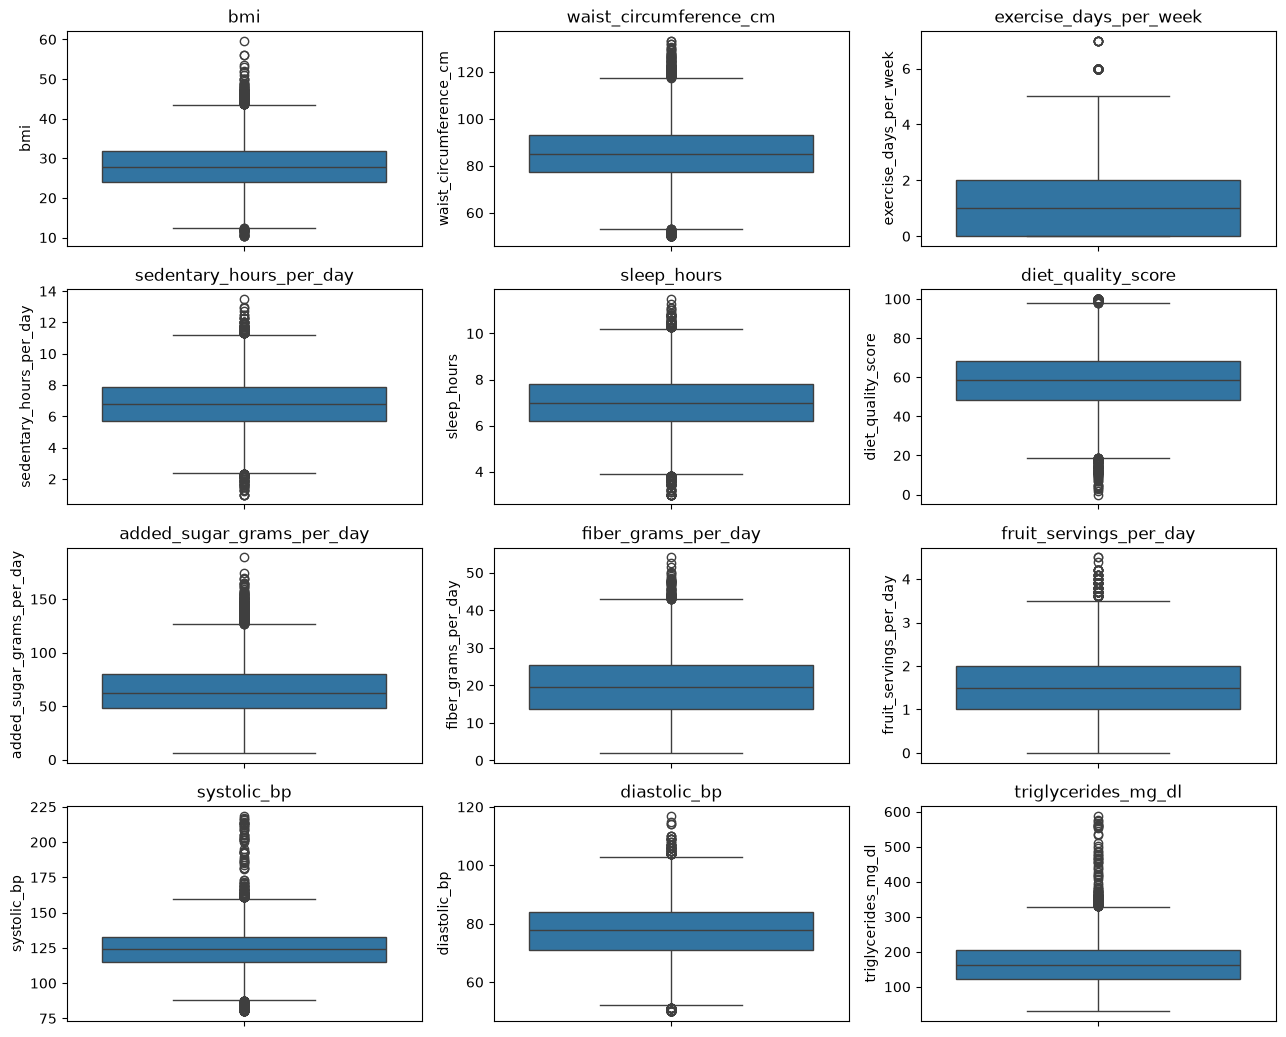

In [62]:
plt.figure(figsize = (13,13)) #canvas size
for i, col in enumerate(numeric_cols1, 1):
    plt.subplot(5, 3, i) # 5 rows, 3 columns
    sns.boxplot(y = df2[col])
    plt.title(col)

plt.tight_layout()  #prevent overlapping
plt.show()

In [63]:
# analysis of outliers using IQR method

outlier_results = []

for cols in numeric_cols1:
    Q1 = df2[cols].quantile(0.25)
    Q3 = df2[cols].quantile(0.75)
    IQR = Q3 - Q1

    lb = Q1 - (1.5 * IQR) #lower bound
    ub = Q3 + (1.5 * IQR) #upper bound

    outliers = df2[(df2[cols] < lb) | (df2[cols] > ub)] #filtering the outliers
    outlier_cnt = len(outliers) # no. of outliers in each column
    outlier_per = (outlier_cnt/len(df2)*100) # percentage of outlier

    outlier_results.append({
        'Feature': cols,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower bound': lb,
        'Upper bound': ub,
        'Outlier count': outlier_cnt,
        'Outlier per': outlier_per
    })
# to convert this to table
outlier_df = pd.DataFrame(outlier_results)
outlier_df

,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier per
0,bmi,24.03,31.84,7.81,12.315,43.555,158,0.790
1,waist_circumference_cm,77.20,93.30,16.10,53.050,117.450,209,1.045
2,exercise_days_per_week,0.00,2.00,2.00,-3.000,5.000,94,0.470
3,sedentary_hours_per_day,5.70,7.90,2.20,2.400,11.200,123,0.615
4,sleep_hours,6.20,7.80,1.60,3.800,10.200,137,0.685
5,diet_quality_score,48.50,68.30,19.80,18.800,98.000,213,1.065
6,added_sugar_grams_per_day,48.20,79.70,31.50,0.950,126.950,288,1.440
7,fiber_grams_per_day,13.80,25.50,11.70,-3.750,43.050,65,0.325
8,fruit_servings_per_day,1.00,2.00,1.00,-0.500,3.500,97,0.485
9,systolic_bp,115.00,133.00,18.00,88.000,160.000,204,1.020


In [64]:
outlier_check = []
for cols in numeric_cols1:
    mini = df2[cols].min()
    maxi = df2[cols].max()
    uni_val = sorted(df2[cols].unique())[:20]
    
    outlier_check.append({
        'Feature': cols,
        'Minimum': mini,
        'Maximum': maxi,
        'Unique values': uni_val
    })
outlier_df = pd.DataFrame(outlier_check)
outlier_df

,Feature,Minimum,Maximum,Unique values
0,bmi,10.32,59.692509,"[10.32, 10.35, 10.44, 10.48, 10.62, 10.74, 10...."
1,waist_circumference_cm,50.00,133.300000,"[50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50...."
2,exercise_days_per_week,0.00,7.000000,"[0, 1, 2, 3, 4, 5, 6, 7]"
3,sedentary_hours_per_day,1.00,13.500000,"[1.0, 1.2, 1.3, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, ..."
4,sleep_hours,3.00,11.500000,"[3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, ..."
5,diet_quality_score,0.00,100.000000,"[0.0, 1.7, 2.7, 3.2, 3.7, 4.6, 4.7, 4.8, 6.9, ..."
6,added_sugar_grams_per_day,6.30,189.000000,"[6.3, 10.2, 10.4, 10.6, 11.1, 11.8, 12.5, 12.8..."
7,fiber_grams_per_day,2.00,54.100000,"[2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, ..."
8,fruit_servings_per_day,0.00,4.500000,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ..."
9,systolic_bp,80.00,218.739617,"[80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 86.0, 87...."


##### Outlier treatment
###### Outliers were identified using the IQR method. The analysis showed a relatively small proportion of potential outliers across the numerical features. These observations were further examined using their minimum and maximum values. Since the extreme values appeared potentially valid and no clear evidence of data-entry errors was identified, the observations were retained without removal or capping to preserve the original data distribution.

### Correlation Analysis (helps us understand the strength and direction of relationships between numerical variables.)

In [65]:
#  correlation matrix: calculates the Pearson correlation coefficients between the 12 numerical predictors and the target

correlation_mtx = df2[numeric_cols1 + ['diabetes_status']].corr()
correlation_mtx

,bmi,waist_circumference_cm,exercise_days_per_week,sedentary_hours_per_day,sleep_hours,diet_quality_score,added_sugar_grams_per_day,fiber_grams_per_day,fruit_servings_per_day,systolic_bp,diastolic_bp,triglycerides_mg_dl,diabetes_status
bmi,1.000000,0.799592,0.002994,-0.000967,-0.003491,-0.184727,0.184820,-0.070872,0.014050,0.367532,0.322780,0.361889,0.326327
waist_circumference_cm,0.799592,1.000000,-0.000232,0.000914,-0.008680,-0.143456,0.254199,-0.049090,0.015767,0.316096,0.284590,0.301920,0.292713
exercise_days_per_week,0.002994,-0.000232,1.000000,-0.211612,0.000395,0.081990,0.112356,0.028931,0.007696,-0.030029,-0.015946,-0.017459,-0.061236
sedentary_hours_per_day,-0.000967,0.000914,-0.211612,1.000000,0.000621,-0.036794,-0.073040,-0.013402,-0.011823,0.008316,0.011335,0.010467,0.027630
sleep_hours,-0.003491,-0.008680,0.000395,0.000621,1.000000,0.000012,-0.007250,-0.001325,0.001757,-0.008569,-0.008119,-0.010699,-0.038336
diet_quality_score,-0.184727,-0.143456,0.081990,-0.036794,0.000012,1.000000,0.002974,0.347045,0.004236,-0.138899,-0.123370,-0.121268,-0.176292
added_sugar_grams_per_day,0.184820,0.254199,0.112356,-0.073040,-0.007250,0.002974,1.000000,0.004658,0.013665,0.017860,0.020726,0.055441,0.026955
fiber_grams_per_day,-0.070872,-0.049090,0.028931,-0.013402,-0.001325,0.347045,0.004658,1.000000,0.002181,-0.051953,-0.044045,-0.041391,-0.054645
fruit_servings_per_day,0.014050,0.015767,0.007696,-0.011823,0.001757,0.004236,0.013665,0.002181,1.000000,0.011954,0.015381,-0.001118,0.009887
systolic_bp,0.367532,0.316096,-0.030029,0.008316,-0.008569,-0.138899,0.017860,-0.051953,0.011954,1.000000,0.354255,0.188871,0.303124


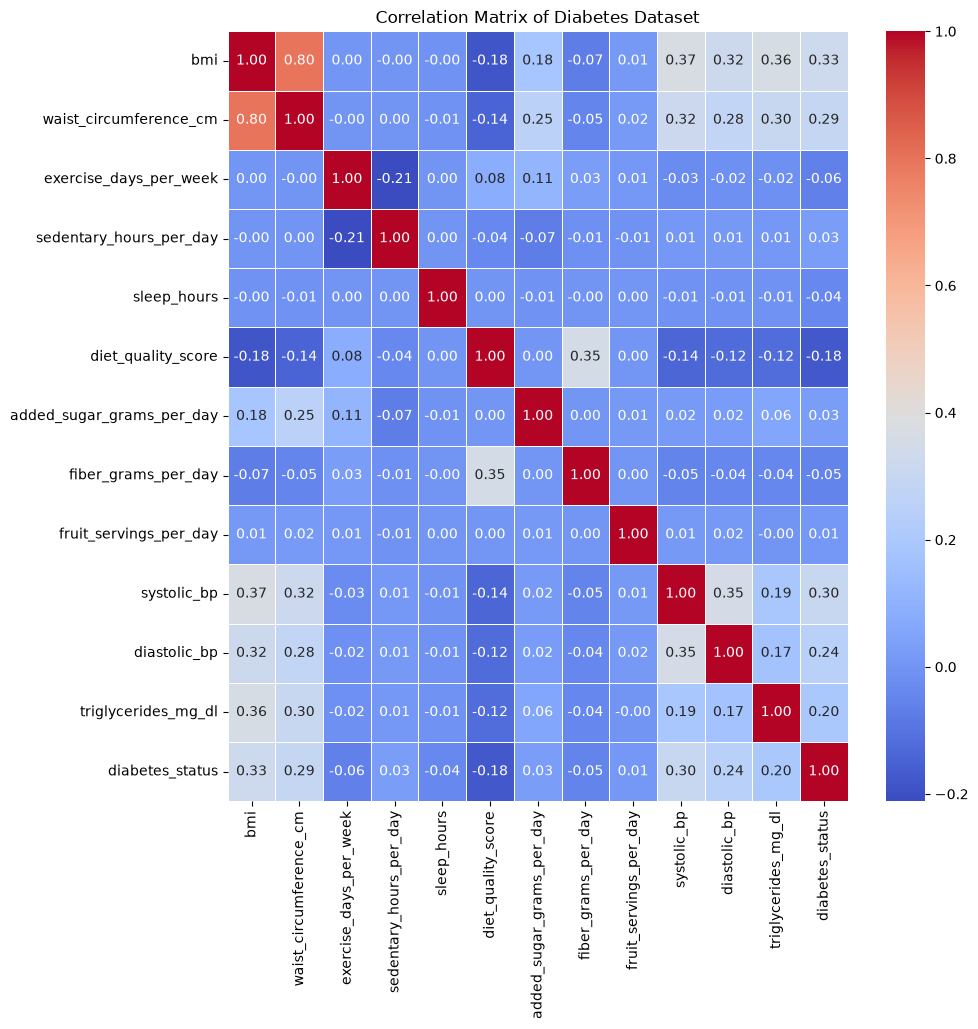

In [66]:
# corelation heatmap

plt.figure(figsize=(10, 10))

sns.heatmap(
    correlation_mtx,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Diabetes Dataset')
plt.show()             

In [67]:
# Correlation of features with target variable
target_correlation = correlation_mtx['diabetes_status'].drop(
    'diabetes_status'
).sort_values(ascending=False)

print(target_correlation)

bmi                          0.326327
systolic_bp                  0.303124
waist_circumference_cm       0.292713
diastolic_bp                 0.243758
triglycerides_mg_dl          0.195498
sedentary_hours_per_day      0.027630
added_sugar_grams_per_day    0.026955
fruit_servings_per_day       0.009887
sleep_hours                 -0.038336
fiber_grams_per_day         -0.054645
exercise_days_per_week      -0.061236
diet_quality_score          -0.176292
Name: diabetes_status, dtype: float64


In [68]:
# categorical column analysis
categorical_cols1 =  df2.select_dtypes(include=["str"]).columns
print("Categorical columns:", categorical_cols1)
# Display category distributions

for col in categorical_cols1:
    print(f"\nFeature: {col}")
    print(df2[col].value_counts())

Categorical columns: Index(['age_group', 'gender', 'family_history_diabetes',
       'family_history_obesity', 'family_history_hypertension',
       'physical_activity_level', 'smoking_status', 'stress_level'],
      dtype='str')

Feature: age_group
age_group
41-50    5036
51-60    4792
31-40    3407
61-70    2992
18-30    2086
71-90    1687
Name: count, dtype: int64

Feature: gender
gender
Female    10145
Male       9655
Non-Bi      200
Name: count, dtype: int64

Feature: family_history_diabetes
family_history_diabetes
No     11636
Yes     8364
Name: count, dtype: int64

Feature: family_history_obesity
family_history_obesity
No     14458
Yes     5542
Name: count, dtype: int64

Feature: family_history_hypertension
family_history_hypertension
No     11279
Yes     8721
Name: count, dtype: int64

Feature: physical_activity_level
physical_activity_level
Lightly Active       6708
Sedentary            4799
Moderately Active    4649
Very Active          2905
Extremely Active      939
Name: co

#### EDA summary
- A sample dataset of 20,000 stratified dataset were selcted whuch contains 20 predictor features and one target variable
- Missing values were handled usind median and mode
- The outliers were examined using IQR method; however, the observations were retained because no clear data-entry errors
- Correlation analysis identified bmi, systolic bp and waist circumference as strongest linear association with target variable
- Categorical variables were examined to understand the encoding methods

This prepared dataset will used in the next stage of preprocessing model building

In [70]:
# save the cleaned and selected dataset
df2.to_csv('../data/diabetes_cleaned.csv', index = False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [72]:
# to verify actually the file exists or not
import os
print(os.path.exists('../data/diabetes_cleaned.csv'))

True
